In [2]:

import pandas as pd

train = pd.read_csv('/content/kathmandu_weather_train_orignal.csv')
test = pd.read_csv('/content/kathmandu_weather_test_orignal.csv')

print("Training data shape:", train.shape)
print("Testing data shape:", test.shape)

display(train.head())


Training data shape: (26304, 9)
Testing data shape: (8760, 9)


,time,temperature_2m,dew_point_2m,cloud_cover,weather_code,precipitation,hour,month,us_aqi
0,2022-10-01 00:00:00,17.2,16.9,21,1,0.0,0,10,80.0
1,2022-10-01 01:00:00,17.3,16.9,9,0,0.0,1,10,81.0
2,2022-10-01 02:00:00,17.1,16.7,14,0,0.0,2,10,82.0
3,2022-10-01 03:00:00,16.8,16.4,6,0,0.0,3,10,83.0
4,2022-10-01 04:00:00,16.6,16.1,2,0,0.0,4,10,84.0


In [ ]:

# Select the six features required
features = [
    'temperature_2m',
    'dew_point_2m',
    'cloud_cover',
    'precipitation',
    'hour',
    'month'
]

# Creating feature datasets
X_train = train[features].copy()
X_test = test[features].copy()

# Keeping actual AQI values separately for later analysis
y_train = train['us_aqi'].copy()
y_test = test['us_aqi'].copy()

# Display selected features
print("Selected features:")
print(features)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

display(X_train.head())


Selected features:
['temperature_2m', 'dew_point_2m', 'cloud_cover', 'precipitation', 'hour', 'month']

Training feature shape: (26304, 6)
Testing feature shape: (8760, 6)


,temperature_2m,dew_point_2m,cloud_cover,precipitation,hour,month
0,17.2,16.9,21,0.0,0,10
1,17.3,16.9,9,0.0,1,10
2,17.1,16.7,14,0.0,2,10
3,16.8,16.4,6,0.0,3,10
4,16.6,16.1,2,0.0,4,10


In [ ]:

from sklearn.preprocessing import StandardScaler

# scaling the features so they are on a similar scale
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# checking the scaled data
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nFirst 5 scaled rows:")
print(X_train_scaled[:5])


Training data shape: (26304, 6)
Testing data shape: (8760, 6)

First 5 scaled rows:
[[-0.16740284  0.58963563 -0.6365049  -0.22721948 -1.66132477  1.00844189]
 [-0.15012803  0.58963563 -0.92151203 -0.22721948 -1.51686175  1.00844189]
 [-0.18467764  0.55931812 -0.80275906 -0.22721948 -1.37239873  1.00844189]
 [-0.23650204  0.51384184 -0.99276381 -0.22721948 -1.2279357   1.00844189]
 [-0.27105164  0.46836556 -1.08776619 -0.22721948 -1.08347268  1.00844189]]


K = 2 | Inertia = 114105.91 | Silhouette = 0.2797
K = 3 | Inertia = 93823.94 | Silhouette = 0.3001
K = 4 | Inertia = 76668.57 | Silhouette = 0.3166
K = 5 | Inertia = 67124.91 | Silhouette = 0.2825
K = 6 | Inertia = 58668.81 | Silhouette = 0.2803
K = 7 | Inertia = 52570.12 | Silhouette = 0.2848
K = 8 | Inertia = 47813.80 | Silhouette = 0.2972
K = 9 | Inertia = 43986.95 | Silhouette = 0.3003
K = 10 | Inertia = 40299.75 | Silhouette = 0.3044


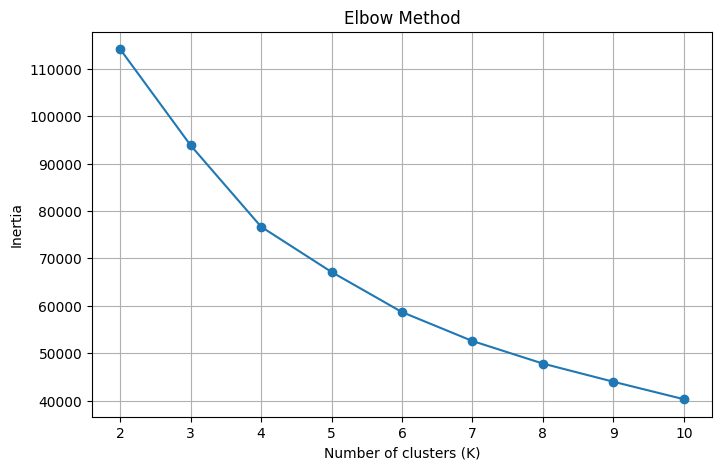

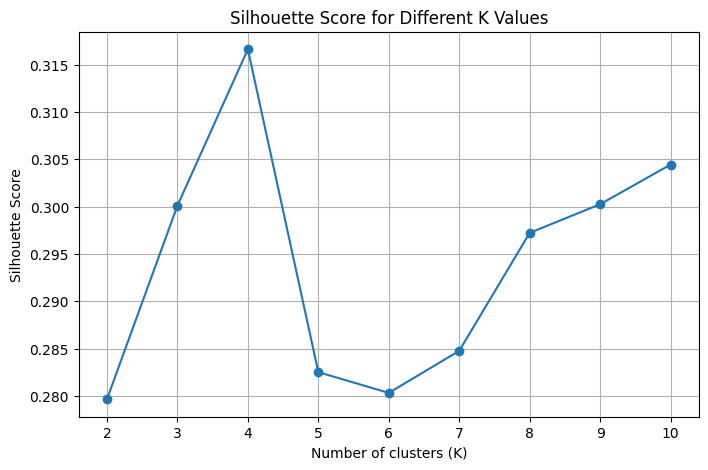

In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# trying different numbers of clusters
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:
    # creating and fitting the model
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_train_scaled)

    # saving the scores
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(
            X_train_scaled,
            labels,
            sample_size=5000,
            random_state=42
        )
    )

# showing the scores for each k
for k, inertia, silhouette in zip(
    k_values, inertia_values, silhouette_values
):
    print(f"K = {k} | Inertia = {inertia:.2f} | Silhouette = {silhouette:.4f}")

# plotting the elbow graph
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.grid(True)
plt.show()

# plotting the silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_values, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K Values')
plt.grid(True)
plt.show()


In [ ]:

# creating our final k-means model with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

train_clusters = kmeans.fit_predict(X_train_scaled)

test_clusters = kmeans.predict(X_test_scaled)

# finding the cluster centres
centres = scaler.inverse_transform(kmeans.cluster_centers_)

centres_df = pd.DataFrame(centres, columns=features)

print("Cluster centres:")
display(centres_df.round(2))

# checking the average AQI in each cluster
train['cluster'] = train_clusters

print("AQI by cluster:")
display(
    train.groupby('cluster')['us_aqi']
    .agg(['mean', 'min', 'max', 'count'])
    .round(2)
)


Cluster centres:


,temperature_2m,dew_point_2m,cloud_cover,precipitation,hour,month
0,14.05,9.22,21.10,0.01,11.51,11.22
1,14.96,6.90,23.77,0.02,11.33,2.61
2,22.18,18.89,75.49,0.30,11.60,7.25
3,22.74,20.37,97.00,8.03,11.92,7.40


AQI by cluster:


,mean,min,max,count
cluster,,,,
0,116.06,12.0,198.0,5294
1,118.71,55.0,208.0,8670
2,85.25,18.0,208.0,11956
3,66.90,18.0,152.0,384


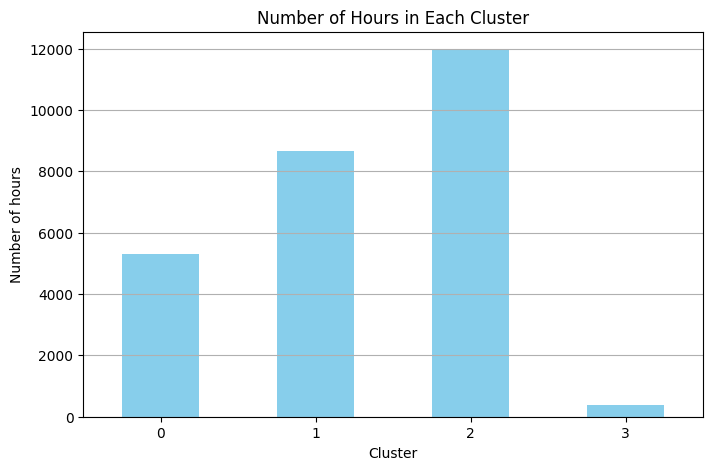

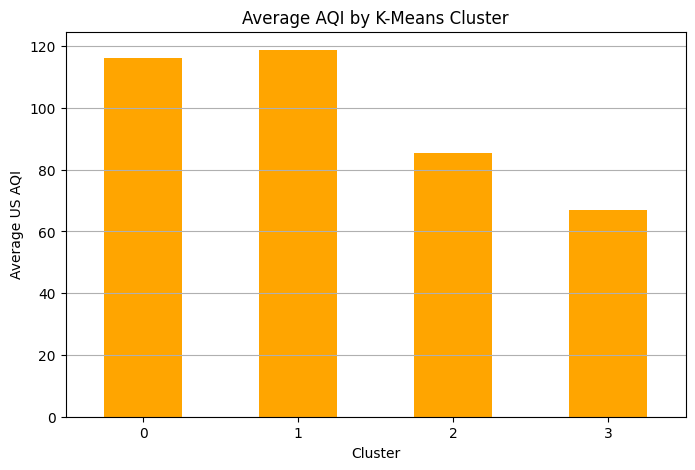

In [ ]:

import matplotlib.pyplot as plt

# showing how many hours belong to each cluster
plt.figure(figsize=(8, 5))
train['cluster'].value_counts().sort_index().plot(
    kind='bar',
    color='skyblue'
)
plt.xlabel('Cluster')
plt.ylabel('Number of hours')
plt.title('Number of Hours in Each Cluster')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

# comparing average AQI between clusters
aqi_means = train.groupby('cluster')['us_aqi'].mean()

plt.figure(figsize=(8, 5))
aqi_means.plot(kind='bar', color='orange')
plt.xlabel('Cluster')
plt.ylabel('Average US AQI')
plt.title('Average AQI by K-Means Cluster')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()


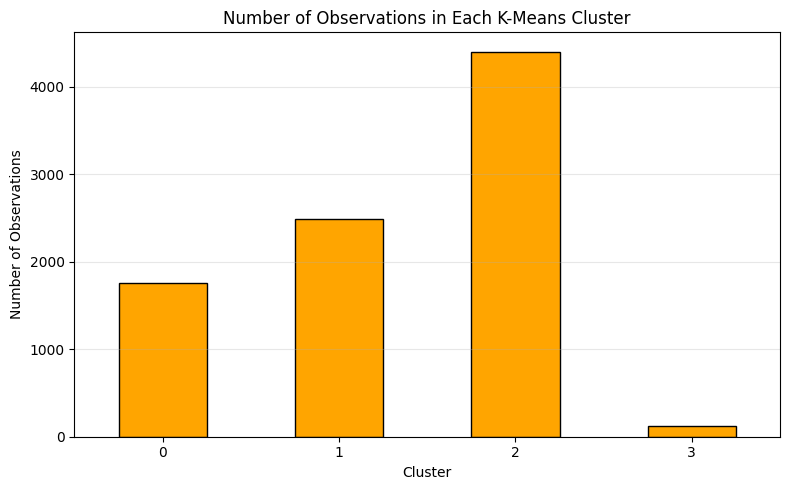

0    1754
1    2484
2    4402
3     120
Name: count, dtype: int64


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Count the number of observations in each cluster
cluster_counts = pd.Series(test_clusters).value_counts().sort_index()

# Create the bar chart
plt.figure(figsize=(8, 5))
cluster_counts.plot(kind='bar', color='orange', edgecolor='black')

plt.title('Number of Observations in Each K-Means Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Observations')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Display the exact counts
print(cluster_counts)


In [ ]:

# adding the cluster results to testing data
test['cluster'] = test_clusters

# checking AQI for each cluster in testing data
print("Testing AQI by cluster:")

display(
    test.groupby('cluster')['us_aqi']
    .agg(['mean', 'min', 'max', 'count'])
    .round(2)
)

# showing the number of hours in each cluster
print("\nTesting cluster distribution:")
print(test['cluster'].value_counts().sort_index())


Testing AQI by cluster:


,mean,min,max,count
cluster,,,,
0,124.71,53.0,178.0,1754
1,144.54,58.0,217.0,2484
2,96.15,45.0,217.0,4402
3,75.08,45.0,157.0,120



Testing cluster distribution:
cluster
0    1754
1    2484
2    4402
3     120
Name: count, dtype: int64


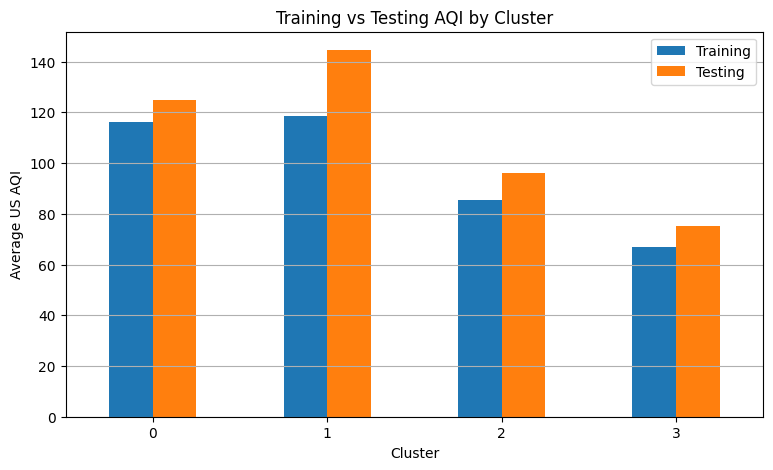

In [ ]:

# comparing average AQI in training and testing data
train_aqi = train.groupby('cluster')['us_aqi'].mean()
test_aqi = test.groupby('cluster')['us_aqi'].mean()

comparison = pd.DataFrame({
    'Training': train_aqi,
    'Testing': test_aqi
})

comparison.plot(kind='bar', figsize=(9, 5))

plt.xlabel('Cluster')
plt.ylabel('Average US AQI')
plt.title('Training vs Testing AQI by Cluster')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')
plt.show()


In [ ]:

# making a summary of our training results
train_summary = train.groupby('cluster')['us_aqi'].agg(
    ['mean', 'min', 'max', 'count']
).round(2)

# doing the same for testing results
test_summary = test.groupby('cluster')['us_aqi'].agg(
    ['mean', 'min', 'max', 'count']
).round(2)

print("Training results:")
display(train_summary)

print("Testing results:")
display(test_summary)

# saving the results for our report
train_summary.to_csv('kmeans_training_results.csv')
test_summary.to_csv('kmeans_testing_results.csv')
centres_df.to_csv('kmeans_cluster_centres.csv', index=False)

print("All three result files have been saved!")


Training results:


,mean,min,max,count
cluster,,,,
0,116.06,12.0,198.0,5294
1,118.71,55.0,208.0,8670
2,85.25,18.0,208.0,11956
3,66.90,18.0,152.0,384


Testing results:


,mean,min,max,count
cluster,,,,
0,124.71,53.0,178.0,1754
1,144.54,58.0,217.0,2484
2,96.15,45.0,217.0,4402
3,75.08,45.0,157.0,120


All three result files have been saved!


In [ ]:

from google.colab import files

files.download('kmeans_training_results.csv')
files.download('kmeans_testing_results.csv')
files.download('kmeans_cluster_centres.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

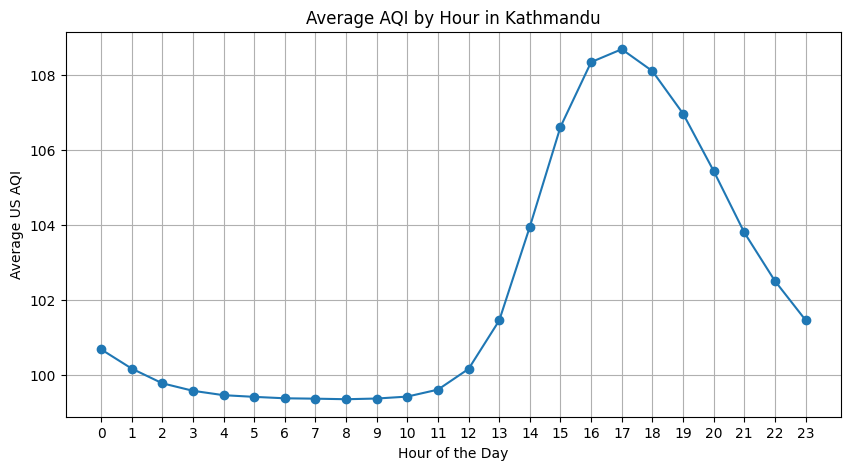

In [ ]:
# finding the average AQI for each hour
hourly_aqi = train.groupby('hour')['us_aqi'].mean()

# plotting the graph
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(hourly_aqi.index, hourly_aqi.values, marker='o')

plt.title('Average AQI by Hour in Kathmandu')
plt.xlabel('Hour of the Day')
plt.ylabel('Average US AQI')
plt.xticks(range(24))
plt.grid(True)
plt.show()

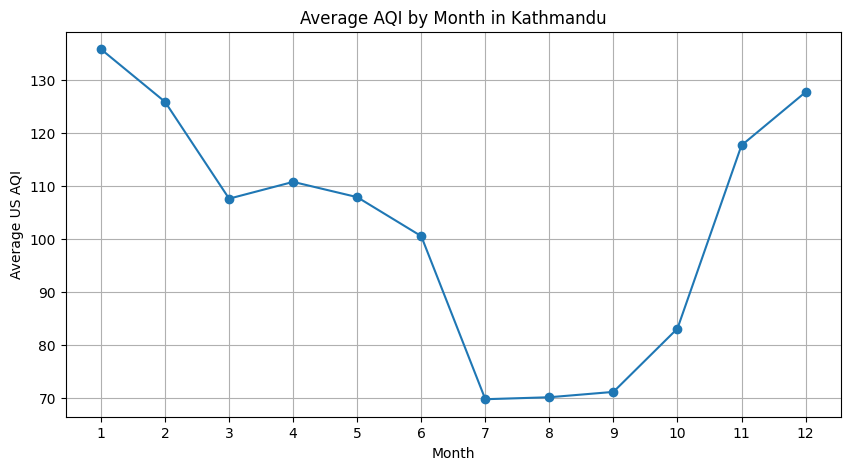

In [ ]:
# finding the average AQI for each month
monthly_aqi = train.groupby('month')['us_aqi'].mean()

# plotting the graph
plt.figure(figsize=(10, 5))
plt.plot(monthly_aqi.index, monthly_aqi.values, marker='o')

plt.title('Average AQI by Month in Kathmandu')
plt.xlabel('Month')
plt.ylabel('Average US AQI')
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

In [ ]:
print("Average AQI by Hour:")
print(hourly_aqi.round(2))

print("\nAverage AQI by Month:")
print(monthly_aqi.round(2))

Average AQI by Hour:
hour
0     100.69
1     100.18
2      99.79
3      99.59
4      99.47
5      99.42
6      99.39
7      99.38
8      99.36
9      99.38
10     99.43
11     99.62
12    100.17
13    101.46
14    103.95
15    106.61
16    108.33
17    108.67
18    108.09
19    106.96
20    105.43
21    103.80
22    102.51
23    101.47
Name: us_aqi, dtype: float64

Average AQI by Month:
month
1     135.80
2     125.88
3     107.63
4     110.79
5     107.91
6     100.56
7      69.82
8      70.19
9      71.20
10     83.14
11    117.67
12    127.71
Name: us_aqi, dtype: float64


In [ ]:
from google.colab import files
files.download('average_aqi_by_hour.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile

with zipfile.ZipFile('EDA_2_Graphs.zip', 'w') as zip_file:
    zip_file.write('average_aqi_by_hour.png')
    zip_file.write('average_aqi_by_month.png')

from google.colab import files
files.download('EDA_2_Graphs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
train_summary = train.groupby('cluster')['us_aqi'].agg(
    ['mean', 'min', 'max', 'count']
).round(2)

train_summary

,mean,min,max,count
cluster,,,,
0,116.06,12.0,198.0,5294
1,118.71,55.0,208.0,8670
2,85.25,18.0,208.0,11956
3,66.90,18.0,152.0,384


In [ ]:
test_summary = test.groupby('cluster')['us_aqi'].agg(
    mean='mean',
    min='min',
    max='max',
    count='count'
).round(2)

print("Testing Dataset Cluster Results:")
display(test_summary)

Testing Dataset Cluster Results:


,mean,min,max,count
cluster,,,,
0,124.71,53.0,178.0,1754
1,144.54,58.0,217.0,2484
2,96.15,45.0,217.0,4402
3,75.08,45.0,157.0,120


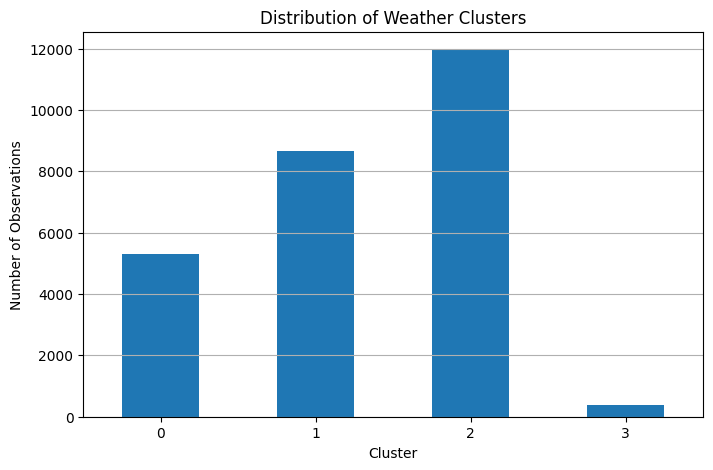

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
train['cluster'].value_counts().sort_index().plot(kind='bar')

plt.title('Distribution of Weather Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Observations')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

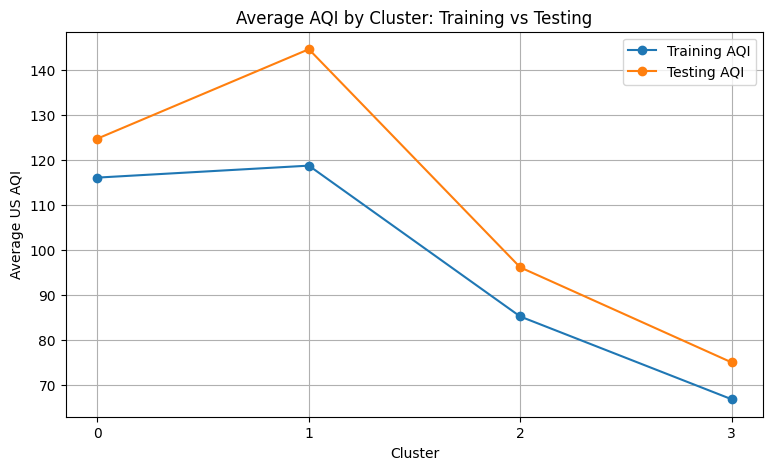

In [ ]:
import matplotlib.pyplot as plt

train_aqi = train.groupby('cluster')['us_aqi'].mean()
test_aqi = test.groupby('cluster')['us_aqi'].mean()

plt.figure(figsize=(9, 5))

plt.plot(train_aqi.index, train_aqi.values, marker='o', label='Training AQI')
plt.plot(test_aqi.index, test_aqi.values, marker='o', label='Testing AQI')

plt.title('Average AQI by Cluster: Training vs Testing')
plt.xlabel('Cluster')
plt.ylabel('Average US AQI')
plt.xticks([0, 1, 2, 3])
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd

cluster_table = centres_df.copy()

cluster_table.insert(0, 'Cluster', range(4))

cluster_table = cluster_table.round(2)

print(cluster_table.to_string(index=False))

 Cluster  temperature_2m  dew_point_2m  cloud_cover  precipitation  hour  month
       0           14.05          9.22        21.10           0.01 11.51  11.22
       1           14.96          6.90        23.77           0.02 11.33   2.61
       2           22.18         18.89        75.49           0.30 11.60   7.25
       3           22.74         20.37        97.00           8.03 11.92   7.40


In [ ]:

# Assign testing observations to their K-Means clusters
test_clusters = kmeans.predict(X_test_scaled)

print("Testing clusters created successfully!")


Testing clusters created successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving kathmandu_weather_test_orignal.csv to kathmandu_weather_test_orignal (1).csv
Saving kathmandu_weather_train_orignal.csv to kathmandu_weather_train_orignal (1).csv


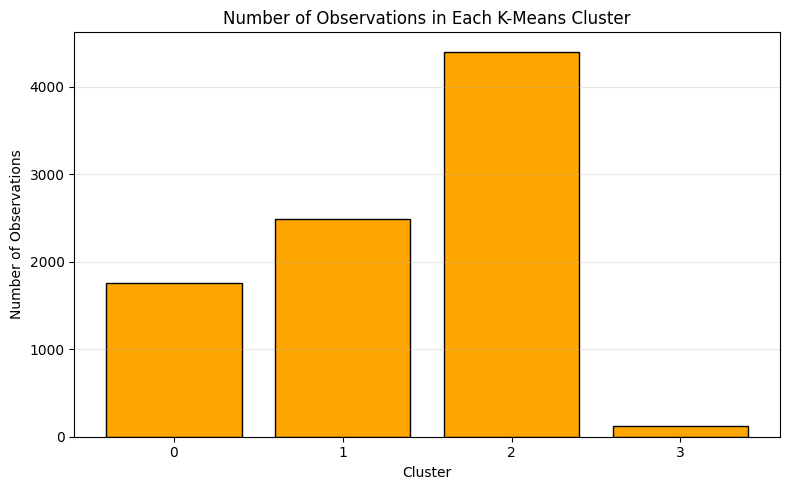

0    1754
1    2484
2    4402
3     120
Name: count, dtype: int64


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Count testing observations in each cluster
cluster_counts = pd.Series(test_clusters).value_counts().sort_index()

# Create the graph
plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index, cluster_counts.values,
        color='orange', edgecolor='black')

plt.title('Number of Observations in Each K-Means Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Observations')
plt.xticks([0, 1, 2, 3])
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(cluster_counts)


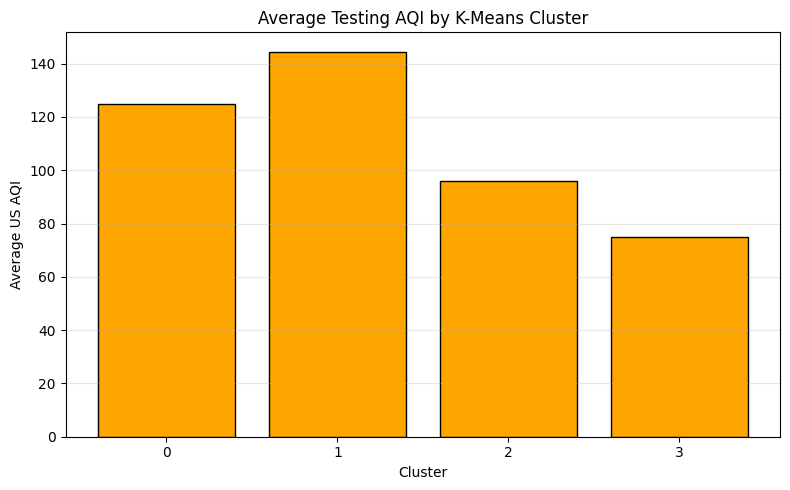

In [ ]:

import matplotlib.pyplot as plt

# Average testing AQI for each K-Means cluster
clusters = [0, 1, 2, 3]
average_aqi = [124.71, 144.54, 96.15, 75.08]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(clusters, average_aqi, color='orange', edgecolor='black')

plt.title('Average Testing AQI by K-Means Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average US AQI')
plt.xticks(clusters)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
